In [ ]:
import pandas as pd

# Load compressed CSV file
df = pd.read_csv('ibtracs.last3years.list.v04r01.csv')

# Display the first few rows
# print(df.head())

In [3]:
df_new = df[["NAME", "ISO_TIME", "USA_LAT", "USA_LON", "USA_WIND", "STORM_SPEED", "STORM_DIR"]]

In [4]:
hurricane_helene_rows = df_new[df_new['NAME'].str.contains('Helene', case=False, na=False)]

helene_track = hurricane_helene_rows 

print(hurricane_helene_rows)

         NAME             ISO_TIME USA_LAT USA_LON USA_WIND STORM_SPEED  \
15740  HELENE  2024-09-23 12:00:00    17.2   -81.7       30           7   
15741  HELENE  2024-09-23 15:00:00    17.5   -81.8       33           6   
15742  HELENE  2024-09-23 18:00:00    17.8   -81.9       35           5   
15743  HELENE  2024-09-23 21:00:00    18.0   -82.0       35           5   
15744  HELENE  2024-09-24 00:00:00    18.2   -82.2       35           6   
15745  HELENE  2024-09-24 03:00:00    18.4   -82.5       35           7   
15746  HELENE  2024-09-24 06:00:00    18.6   -82.8       35           9   
15747  HELENE  2024-09-24 09:00:00    18.9   -83.2       38          10   
15748  HELENE  2024-09-24 12:00:00    19.2   -83.7       40          10   
15749  HELENE  2024-09-24 15:00:00    19.3   -84.2       43           9   
15750  HELENE  2024-09-24 18:00:00    19.4   -84.6       45           7   
15751  HELENE  2024-09-24 21:00:00    19.5   -84.9       48           6   
15752  HELENE  2024-09-25

In [5]:
# for col in df.columns:
#    print(col)

In [6]:
df.info

<bound method DataFrame.info of                  SID SEASON NUMBER BASIN SUBBASIN     NAME  \
0                      Year                                  
1      2022008S13148   2022      1    SP       EA  TIFFANY   
2      2022008S13148   2022      1    SP       EA  TIFFANY   
3      2022008S13148   2022      1    SP       EA  TIFFANY   
4      2022008S13148   2022      1    SP       EA  TIFFANY   
...              ...    ...    ...   ...      ...      ...   
18451  2025087S14124   2025     21    SI       WA   DIANNE   
18452  2025087S14124   2025     21    SI       WA   DIANNE   
18453  2025087S14124   2025     21    SI       WA   DIANNE   
18454  2025087S14124   2025     21    SI       WA   DIANNE   
18455  2025087S14124   2025     21    SI       WA   DIANNE   

                  ISO_TIME NATURE            LAT           LON  ...  \
0                                  degrees_north  degrees_east  ...   
1      2022-01-08 00:00:00     MX          -12.6         147.7  ...   
2      202

In [7]:
df.dtypes

SID              object
SEASON           object
NUMBER           object
BASIN            object
SUBBASIN         object
                  ...  
USA_SEARAD_SE    object
USA_SEARAD_SW    object
USA_SEARAD_NW    object
STORM_SPEED      object
STORM_DIR        object
Length: 174, dtype: object

In [8]:
for col in df_new.columns:
    print(col)

NAME
ISO_TIME
USA_LAT
USA_LON
USA_WIND
STORM_SPEED
STORM_DIR


In [9]:
print(df_new.head)

<bound method NDFrame.head of           NAME             ISO_TIME        USA_LAT       USA_LON USA_WIND  \
0                                    degrees_north  degrees_east      kts   
1      TIFFANY  2022-01-08 00:00:00          -13.3         147.9       20   
2      TIFFANY  2022-01-08 03:00:00          -13.4         148.0       20   
3      TIFFANY  2022-01-08 06:00:00          -13.4         148.0       20   
4      TIFFANY  2022-01-08 09:00:00          -13.4         148.0       23   
...        ...                  ...            ...           ...      ...   
18451   DIANNE  2025-03-28 12:00:00          -15.6         123.8       39   
18452   DIANNE  2025-03-28 15:00:00          -15.9         123.8       42   
18453   DIANNE  2025-03-28 18:00:00          -16.2         123.8       45   
18454   DIANNE  2025-03-28 21:00:00          -16.6         123.9       45   
18455   DIANNE  2025-03-29 00:00:00          -17.0         124.1       45   

      STORM_SPEED STORM_DIR  
0             k

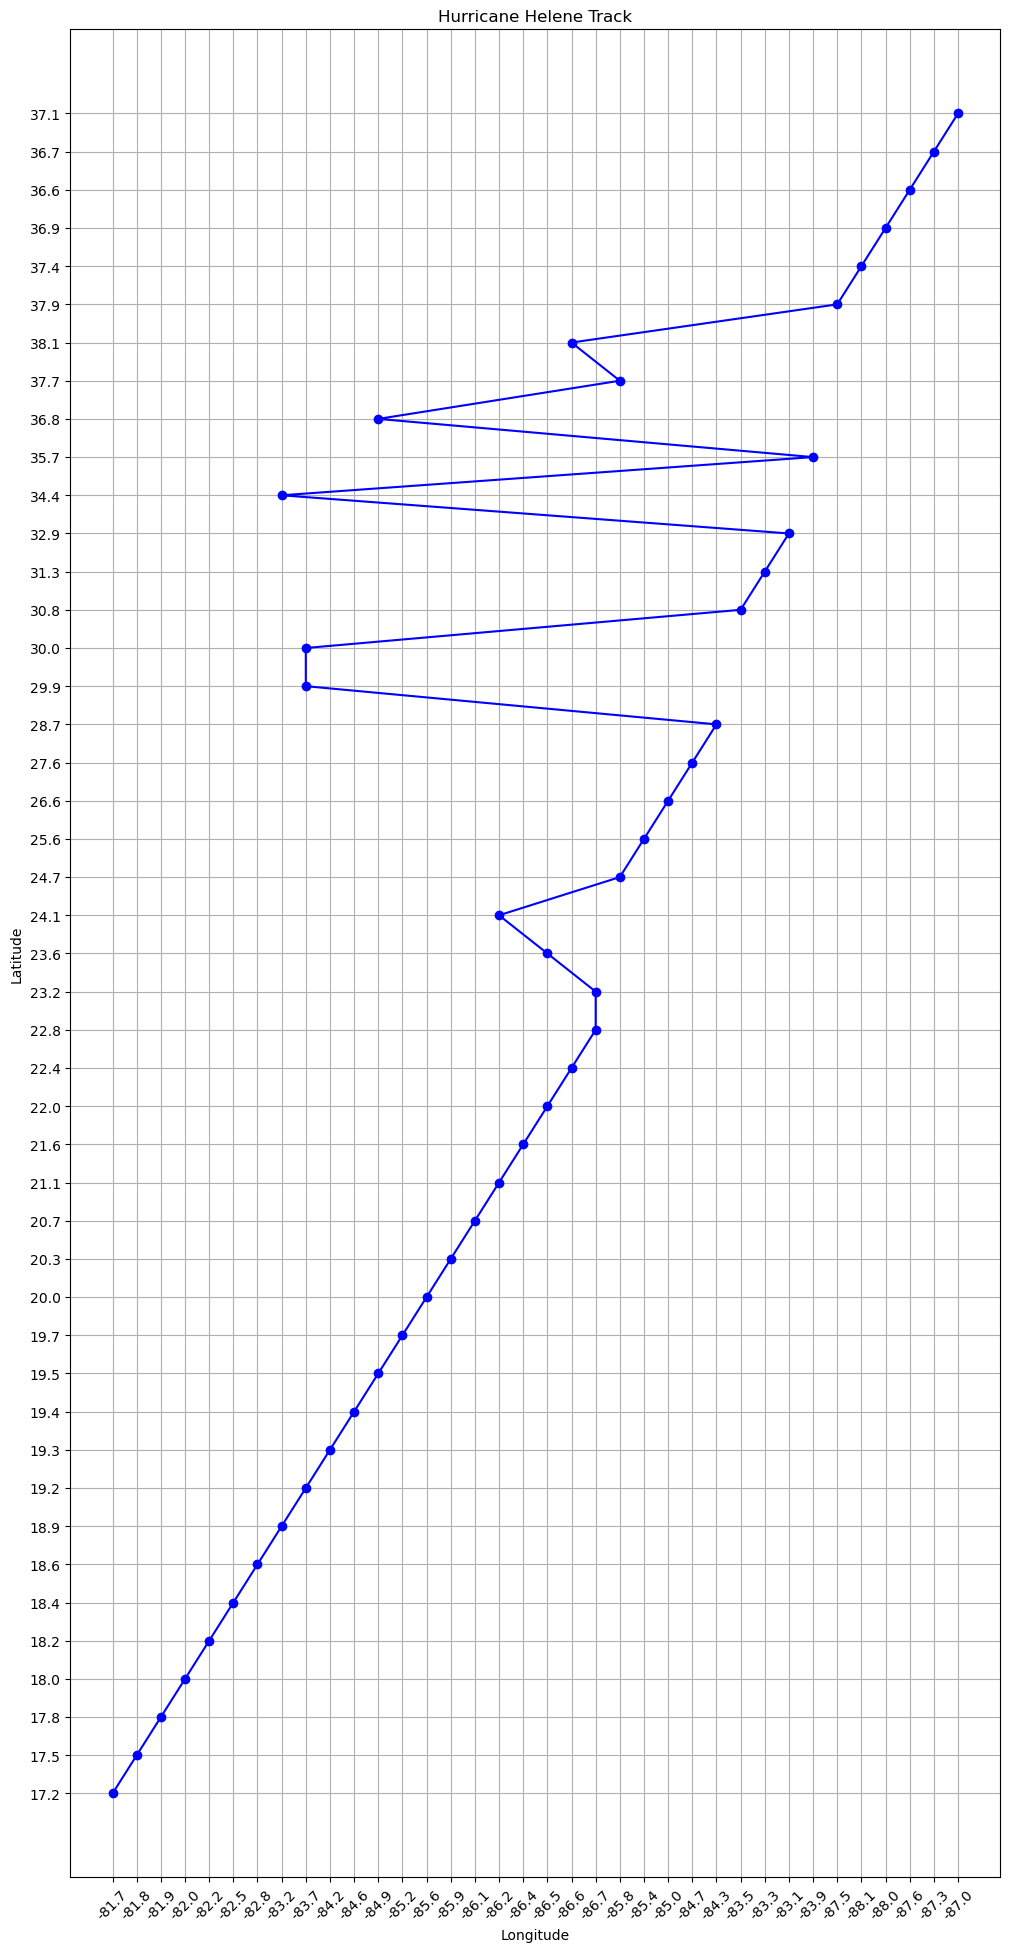

In [10]:
import matplotlib.pyplot as plt

# Assuming you have latitude and longitude data in two lists or pandas Series
# Example data
latitudes = helene_track['USA_LAT']
longitudes = helene_track['USA_LON']

plt.figure(figsize=(12, 24))
plt.plot(longitudes, latitudes, marker='o', color='blue', linestyle='-')
plt.title('Hurricane Helene Track')
plt.xlabel('Longitude')
plt.ylabel('Latitude')
plt.grid(True)
plt.xticks(rotation=45)

plt.show()


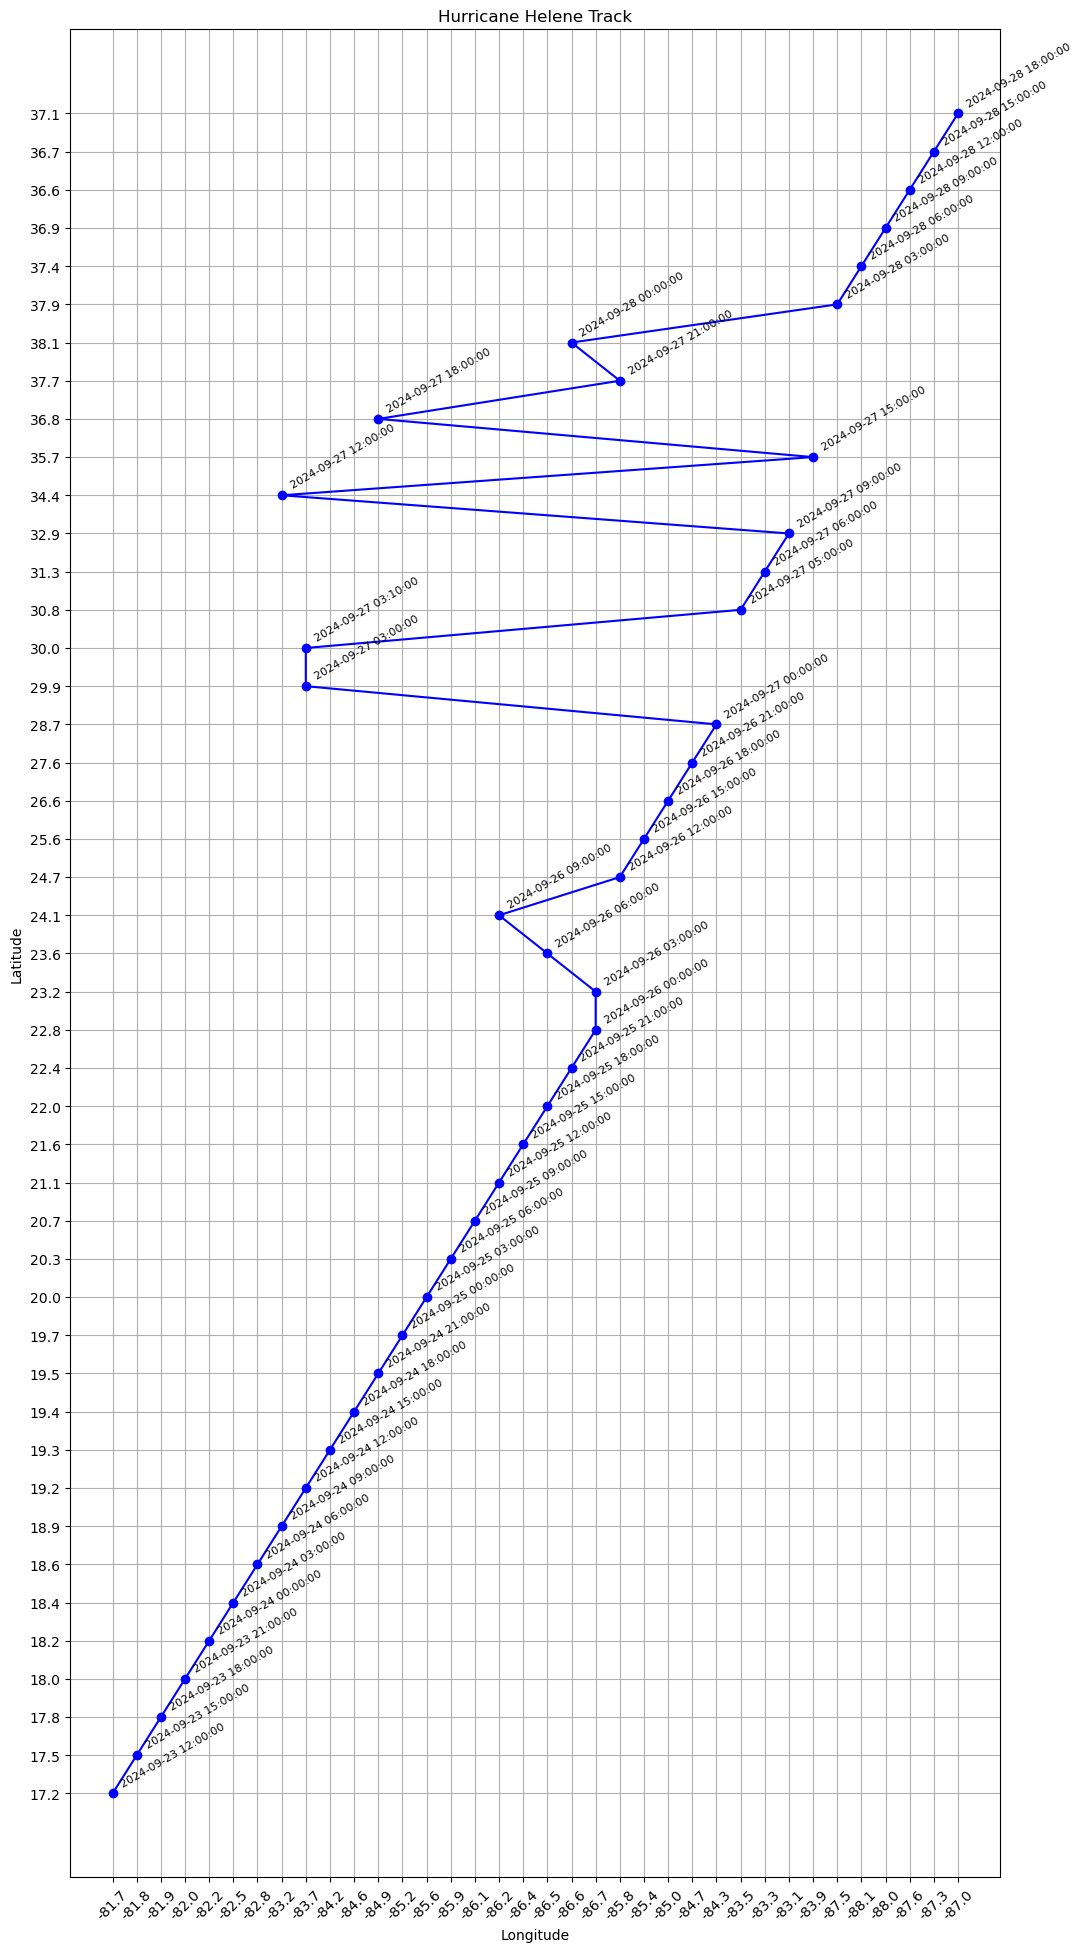

In [11]:
import matplotlib.pyplot as plt

# Example data from helene_track:
# latitudes = helene_track['USA_LAT']
# longitudes = helene_track['USA_LON']
# times = helene_track['ISO_TIME']  # for example, a pandas datetime column

plt.figure(figsize=(12, 24))
plt.plot(longitudes, latitudes, marker='o', color='blue', linestyle='-')

plt.title('Hurricane Helene Track')
plt.xlabel('Longitude')
plt.ylabel('Latitude')
plt.grid(True)
plt.xticks(rotation=45)

# ---------------------------------------------
# OPTION 1: Use plt.annotate() in a loop
# ---------------------------------------------
for i, row in helene_track.iterrows():
    lon = row['USA_LON']
    lat = row['USA_LAT']
    # Convert timestamp to string or just use str(row['ISO_TIME'])
    label_str = row['ISO_TIME']
    
    plt.annotate(
        text=label_str,
        xy=(lon, lat),                 # point to label
        xytext=(5, 5),                # offset label a bit from the point
        textcoords='offset points',   # interpret xytext as offset in points
        fontsize=8,                   # adjust text size as needed
        rotation=30,                  # angle the text if you like
        arrowprops=None               # or add arrowprops to draw an arrow
    )

# Alternatively, you could skip every other point or so to avoid clutter.

plt.show()


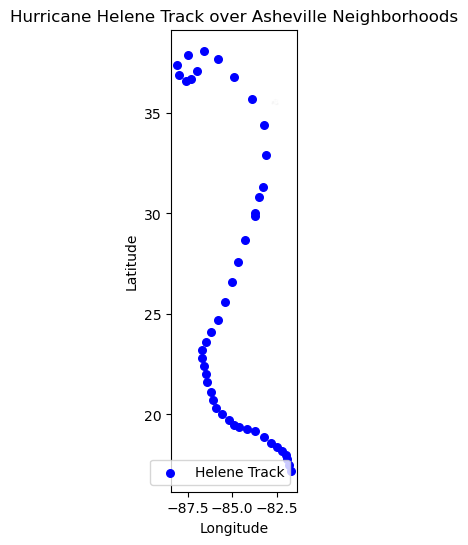

In [12]:
import geopandas as gpd
import matplotlib.pyplot as plt
from shapely.geometry import Point

# 1. Load Asheville neighborhood boundaries
asheville_neighborhoods = gpd.read_file("neighbourhoods.geojson")

# 2. Create a GeoDataFrame for the hurricane track
#    (assuming your 'helene_track' DataFrame has 'USA_LAT' and 'USA_LON' columns)
helene_gdf = gpd.GeoDataFrame(
    helene_track,
    geometry=gpd.points_from_xy(helene_track['USA_LON'], helene_track['USA_LAT']),
    crs="EPSG:4326"  # common coordinate reference for lat/lon
)

# 3. Plot both layers on the same axes
fig, ax = plt.subplots(figsize=(8, 6))

# Plot the Asheville neighborhoods
asheville_neighborhoods.plot(ax=ax, facecolor='lightgray', edgecolor='white', alpha=0.7)

# Plot the hurricane track points
# (you could also create a line from these points if desired)
helene_gdf.plot(ax=ax, color='blue', marker='o', markersize=30, label='Helene Track')

# 4. Customize the plot
ax.set_title("Hurricane Helene Track over Asheville Neighborhoods")
ax.set_xlabel("Longitude")
ax.set_ylabel("Latitude")
ax.legend()
plt.show()


In [13]:
from shapely.geometry import LineString
track_line = LineString(helene_gdf.geometry.tolist())
helene_line = gpd.GeoDataFrame(geometry=[track_line], crs="EPSG:4326")
helene_line.plot(ax=ax, color='blue', linewidth=2)


<Axes: title={'center': 'Hurricane Helene Track over Asheville Neighborhoods'}, xlabel='Longitude', ylabel='Latitude'>

In [ ]:
import matplotlib.pyplot as plt

# Assuming your DataFrame is named helene_track and has columns 'USA_LAT' and 'USA_LON'
latitudes = helene_track['USA_LAT']
longitudes = helene_track['USA_LON']

plt.figure(figsize=(12, 24))

# Plot the track points (o) and connect them with a line (-)
plt.plot(longitudes, latitudes, marker='o', color='blue', linestyle='-')

plt.title('Hurricane Helene Track')
plt.xlabel('Longitude')
plt.ylabel('Latitude')
plt.grid(True)

# Rotate x-axis tick labels (longitudes) so they don't overlap
plt.xticks(rotation=45)

# Display the plot
plt.show()
